IEEE Metadata analyzer

# Utilidades

## Librerias

In [1]:
# # Colab
# from google.colab import drive
# drive.mount('/content/drive/')

# Basicas
import numpy as np
import seaborn as sns
import pandas as pd
import os, time, pickle, umap, pydot, string, joblib, kaleido


import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Ciencia de datos
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.neighbors import NearestNeighbors

from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.sparse import csr_matrix

# Procesamiento de lenguaje
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

# visualizacion
from yellowbrick.cluster import KElbowVisualizer
from wordcloud import WordCloud
import networkx as nx
from IPython.display import Image, display

# otros modelos
# python -m spacy download en_core_web_sm
import gensim, spacy
from gensim import corpora
from gensim.models import LsiModel
from gensim.parsing.preprocessing import preprocess_string

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Pablo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


## Funciones útiles

In [141]:
def AnalisisNan(data):
  data_nan = 100 - data.isna().sum(axis=0) / len(data) * 100
  data_nan = data_nan.sort_values(ascending=False)
  data_nan = data_nan.round(2)
  colors = sns.color_palette("viridis", len(data_nan))
  plt.figure(figsize=(6, int(0.3 * len(data_nan))))
  plt.barh(data_nan.index, data_nan, color=colors)
  for idx, val in enumerate(data_nan):
    plt.text(val, idx, f'{val}%')
  plt.title('Porcentaje de datos disponibles por columna')
  plt.ylabel('Columna')
  plt.xlabel('% de datos disponibles (no NaN)')
  plt.show()

# Cargar el modelo de spaCy
nlp = spacy.load('en_core_web_sm')

# Inicializar NLTK y spaCy herramientas
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Función para eliminar palabras
def remove_custom_words(tokens, remove_words):
    return [word for word in tokens if word not in remove_words]

# Función de lematización y limpieza del texto
def preprocess_text(text):
    # Necesita algunas variables locales
    text = text.lower()  # Poner todo en minusculas
    tokens = word_tokenize(text)  # Tokenización
    tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation]  # Eliminar stopwords y puntuación
    tokens = remove_custom_words(tokens, remove_words)  # Eliminar palabras personalizadas
    tokens = [word.replace('-', ' ') for word in tokens] # Eliminar guiones
    tokens = [lemmatizer.lemmatize(word) for word in tokens]  # Lematización
    return ' '.join(tokens)

def RepresentanteCoseno(X):
  similarity_matrix = cosine_similarity(X)
  # Calcular la similitud promedio de cada abstract con todos los demás
  average_similarity = np.mean(similarity_matrix, axis=1)
  # Encontrar el índice del abstract más representativo
  most_representative_index = np.argmax(average_similarity)
  return(most_representative_index)

def NubePalabrasTFIDF(centroide):
  w = 10
  h = 5
  word_freq = centroide.to_dict()
  wordcloud = WordCloud(width=w * 100, height=h * 100,
                        background_color='white',
                        stopwords=None,
                        min_font_size=10).generate_from_frequencies(word_freq)
  plt.figure(figsize=(w, h), facecolor=None)
  plt.imshow(wordcloud, interpolation="bilinear")
  plt.axis("off")
  plt.tight_layout(pad=0)

  plt.show()

# Tema de investigacion

Términos clave para la búsqueda de papers:

1. Modular multilevel converter
2. Modular multilevel matrix converter
3. Reinforcement learning
4. Physics informed reinforcement learning
5. Actor critic
6. Real time actor critic


In [142]:
folder = 'Topicos'
topics = os.listdir(folder)
topics

['MMC', 'MMMC']

In [143]:
categories = ['Conferences', 'Journals', 'EarlyAccessArticles', 'Books', 'Magazines', 'Standards']

print(categories)

['Conferences', 'Journals', 'EarlyAccessArticles', 'Books', 'Magazines', 'Standards']


In [144]:
datas = []
for topic_idx, topic in enumerate(topics):
  for category_idx, category in enumerate(categories):
    filepath = os.path.join(folder, topic, category + '.csv')
    df = pd.read_csv(filepath, on_bad_lines='skip')
    print(filepath, len(df))
    datas.append(df)

# [len(data) for data in datas]

Topicos\MMC\Conferences.csv 11266
Topicos\MMC\Journals.csv 5653
Topicos\MMC\EarlyAccessArticles.csv 404
Topicos\MMC\Books.csv 348
Topicos\MMC\Magazines.csv 231
Topicos\MMC\Standards.csv 69
Topicos\MMMC\Conferences.csv 2703
Topicos\MMMC\Journals.csv 2021
Topicos\MMMC\EarlyAccessArticles.csv 193
Topicos\MMMC\Books.csv 191
Topicos\MMMC\Magazines.csv 56
Topicos\MMMC\Standards.csv 36


In [145]:
data = pd.concat(datas)
print(len(data))
data.drop_duplicates(inplace=True)
print(len(data))

23171
18171


## Analisis exploratorio

Artículo con mayor cantidad de citas

In [146]:
max_citas = data['Article Citation Count'].dropna().max()
max_citas = data[data['Article Citation Count'] == max_citas]
display(max_citas['Document Title'].values)
max_citas

array(['Recent Advances and Industrial Applications of Multilevel Converters'],
      dtype=object)

,Document Title,Authors,Author Affiliations,Publication Title,Date Added To Xplore,Publication Year,Volume,Issue,Start Page,End Page,...,Mesh_Terms,Article Citation Count,Patent Citation Count,Reference Count,License,Online Date,Issue Date,Meeting Date,Publisher,Document Identifier
3650,Recent Advances and Industrial Applications of...,S. Kouro; M. Malinowski; K. Gopakumar; J. Pou;...,Department of Electrical and Computer Engineer...,IEEE Transactions on Industrial Electronics,12 Jul 2010,2010.0,57,8.0,2553,2580,...,NaN,3206.0,27.0,273.0,IEEE,7 Jun 2010,NaN,NaN,IEEE,IEEE Journals


Mayor cantidad de citas en patentes

In [147]:
max_citas = data['Patent Citation Count'].dropna().max()
max_citas = data[data['Patent Citation Count'] == max_citas]
display(max_citas['Document Title'].values)
max_citas

array(['Cascaded DC-DC converter connection of photovoltaic modules'],
      dtype=object)

,Document Title,Authors,Author Affiliations,Publication Title,Date Added To Xplore,Publication Year,Volume,Issue,Start Page,End Page,...,Mesh_Terms,Article Citation Count,Patent Citation Count,Reference Count,License,Online Date,Issue Date,Meeting Date,Publisher,Document Identifier
3923,Cascaded DC-DC converter connection of photovo...,G. R. Walker; P. C. Sernia,School of Information Technology and Electrica...,IEEE Transactions on Power Electronics,12 Jul 2004,2004.0,19,4.0,1130,1139,...,NaN,747.0,274.0,13.0,IEEE,12 Jul 2004,NaN,NaN,IEEE,IEEE Journals


Mayor cantidad de referencias

In [148]:
max_ref = data['Reference Count'].dropna().max()
max_ref = data[data['Reference Count'] == max_ref]
display(max_ref['Document Title'].values)
max_ref

array(['A Survey and Assessment of Progress in Switching Theory and Logical Design in the Soviet Union'],
      dtype=object)

,Document Title,Authors,Author Affiliations,Publication Title,Date Added To Xplore,Publication Year,Volume,Issue,Start Page,End Page,...,Mesh_Terms,Article Citation Count,Patent Citation Count,Reference Count,License,Online Date,Issue Date,Meeting Date,Publisher,Document Identifier
4208,A Survey and Assessment of Progress in Switchi...,W. H. Kautz,"Stanford Research Institute, Menlo Park, CA, USA",IEEE Transactions on Electronic Computers,26 Dec 2006,1966.0,EC-15,2.0,164,204,...,NaN,8.0,NaN,1741.0,IEEE,26 Dec 2006,NaN,NaN,IEEE,IEEE Journals


In [149]:
len(data), len(data['Abstract'].unique()), len(data['Document Title'].unique()), data['Publication Year'].min(), data['Publication Year'].max()

(18171, 17158, 17403, 1962.0, 2025.0)

In [150]:
mask_oldest = data['Publication Year'] == data['Publication Year'].min()
data.loc[mask_oldest]

,Document Title,Authors,Author Affiliations,Publication Title,Date Added To Xplore,Publication Year,Volume,Issue,Start Page,End Page,...,Mesh_Terms,Article Citation Count,Patent Citation Count,Reference Count,License,Online Date,Issue Date,Meeting Date,Publisher,Document Identifier
4222,Abstracts and references,NaN,NaN,Proceedings of the IRE,22 Jan 2007,1962.0,50,7.0,1731,1744,...,NaN,NaN,NaN,NaN,IEEE,22 Jan 2007,NaN,NaN,IEEE,IEEE Journals


# Preprocesamiento de texto

## Datos NaN

Análisis nan

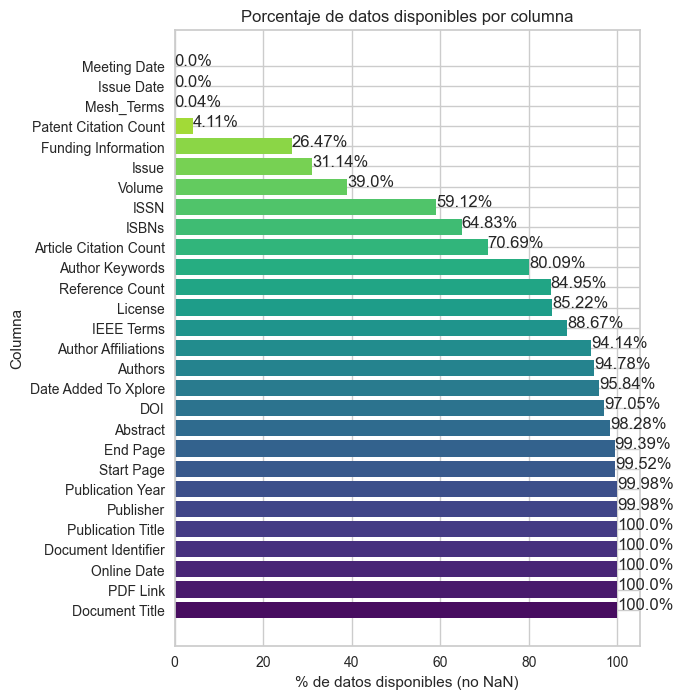

In [151]:
AnalisisNan(data)

Atributos importantes

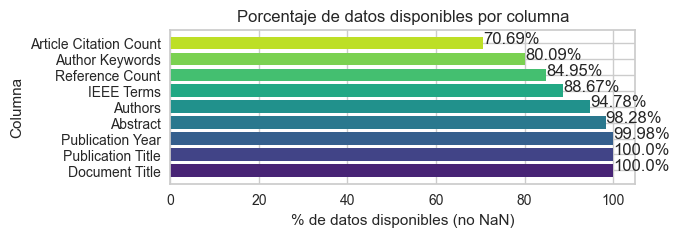

In [152]:
keep_cols = ['Document Title', 'Authors', 'Publication Year', 'Publication Title', 'Abstract', 'Article Citation Count',
             'Reference Count', 'IEEE Terms', 'Author Keywords']
AnalisisNan(data[keep_cols])

## Seleccion de atributos

In [153]:
keep_cols = ['Document Title', 'Abstract', 'Publication Year']
data = data.filter(items=keep_cols)
data.drop_duplicates(subset=keep_cols, inplace=True) 
print(f'Cantidad de datos disponibles: {len(data)}')

Cantidad de datos disponibles: 17649


Eliminar datos nan

In [154]:
data.dropna(inplace=True)
print(f'Cantidad de datos disponibles: {len(data)}')

Cantidad de datos disponibles: 17461


In [155]:
# Reindexar
data = data.reset_index().drop('index', axis=1)
data

,Document Title,Abstract,Publication Year
0,DC Fault Performance of Diode Rectifier based ...,Multi-terminal-direct-current (MTDC) and diode...,2023.0
1,Modeling and Oscillation Mechanism Analysis of...,With the massive access of renewable energy an...,2023.0
2,Three-Phase Four-Wire Inverter for Grid Emulat...,"This paper proposes a new three-phase, four-wi...",2023.0
3,Performance Improvement of Single-Phase Invert...,The demand for electrical power has risen day ...,2023.0
4,Research on the reactive power and voltage cha...,Low-frequency transmission technology has been...,2023.0
...,...,...,...
17456,IEEE Standard Glossary of Computer Networking ...,Terms that pertain to data communications and ...,1995.0
17457,IEEE Draft Guide for Application of Direct Cur...,An approach to apply the DC network topology p...,2024.0
17458,IEEE Recommended Practice for Energy Managemen...,This recommended practice serves as an enginee...,1996.0
17459,IEEE Guide for Computer-Based Control for Hydr...,"The application, design concepts, and implemen...",1997.0


In [156]:
# # Eliminar abstracts y titulos de la plantilla de papers,
# # cargar mascara definida anteriormente

# # Para identificar las filas con abstract o titulo plantilla
# # se realizo un k-means con 50 clusters y se filtro manualmente

# cluster = 9
# cluster = 16
# cluster = 24
# cluster = 31

# drop_mask = (df['cluster_KM'] == 9) | (df['cluster_KM'] == 16) | (df['cluster_KM'] == 24) | (df['cluster_KM'] == 31)
# drop_index = data.loc[drop_mask].index


# cargar indice guardado
drop_index = np.load('drop_index_of_reindexed_data.npy')
data.drop(index=drop_index, inplace=True)

In [157]:
# Eliminar documentos cuyo abstract no tenga las siguientes palabras:

keep_words = ['converter', 'multilevel']

# No hay ninguna de las palabras de la lista (guarda los que tengan alguna de las palabras de la lista)
# pattern = '|'.join(keep_words)
# data = data[data['Abstract'].str.contains(pattern, case=False, na=False)]

# Falta alguna palabra de la lista (guarda los que tienen todas las palabras de la lista)
data = data[data['Abstract'].apply(lambda x: all(word in x.lower() for word in keep_words))]

In [158]:
# Reindexar
data = data.reset_index().drop('index', axis=1)
data

,Document Title,Abstract,Publication Year
0,Simplified dynamic model of a voltage-sourced ...,This paper introduces a simplified HVDC model ...,2009.0
1,A Layered Modular Controller Structure for Mul...,Multilevel converter topology is considered to...,2007.0
2,Control of a modular multilevel cascade BTB sy...,This paper discusses the 6.6-kV BTB (back-to-b...,2010.0
3,Modular Multilevel Converter: An universal con...,For demanding future applications in power tra...,2010.0
4,Extended modular multilevel converters suitabl...,This paper discusses a new transformerless shu...,2010.0
...,...,...,...
7883,IEEE Guide for Technology of Unified Power Flo...,The application of control and protection on a...,2023.0
7884,IEEE Guide for Technology of Unified Power Flo...,An approach to preparing a functional specific...,2019.0
7885,IEEE Draft Guide for Technology of Unified Pow...,An approach to preparing a specification for t...,2020.0
7886,IEEE Draft Guide for Technology of Unified Pow...,The application of control and protection on a...,2022.0


Publicaciones por año

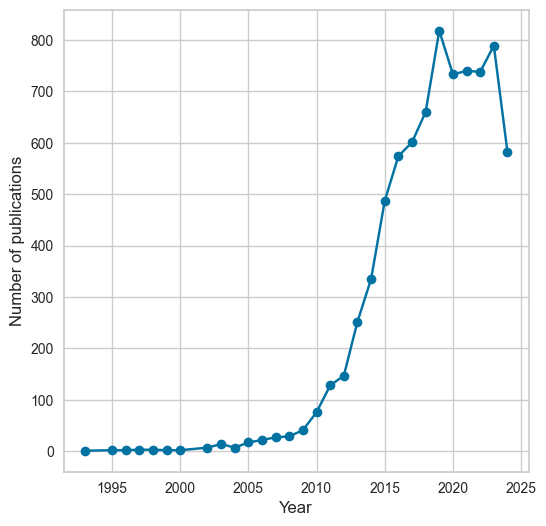

In [159]:
publications_per_year = data['Publication Year'].loc[data['Publication Year']<2025].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.plot(publications_per_year.index, publications_per_year.values, marker='o', linestyle='-', color='b')

# plt.title('Number of publications per year', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of publications', fontsize=12)

plt.grid(True)

plt.savefig('Figuras/publications_per_year.pdf')

plt.show()

In [160]:
keep_cols = ['Document Title', 'Abstract']
data = data.filter(items=keep_cols)
data.drop_duplicates(subset=keep_cols, inplace=True) 
print(f'Cantidad de datos disponibles: {len(data)}')

Cantidad de datos disponibles: 7883


In [161]:
df = data.copy()

In [162]:
# Todo el preprocesamiento (stopwords, puntuacion, minusculas, lematizacion, etc)
remove_words = ["use", "base", "propose", "present", "method", "system", "paper", "is", "in", "as", "by", "for", "at", "the", "they", "are", "to", "can"]
remove_words = []
for column in data.columns:
    df[column] = df[column].apply(preprocess_text)

## Vectorizacion

In [163]:
df_vectorized = pd.DataFrame(df['Abstract'], columns=['Abstract'])

# Vocabulario
vocabulary = ' '.join(df_vectorized['Abstract']).split(' ')

# Vectorizacion TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1, 1))
X_vectorized = vectorizer.fit_transform(df['Abstract'])
words = vectorizer.get_feature_names_out()
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

In [164]:
df_vectorized.columns

Index(['000', '005', '01', '0126', '02', '03', '045', '05', '05p', '05pu',
       ...
       'μh', 'μm', 'μm2', 'μs', 'σk', 'τa', 'ωand', 'ωe', 'ωin', 'ωout'],
      dtype='object', length=12736)

In [165]:
len(words), len(vocabulary)

(12736, 798988)

In [166]:
len(set(words)), len(set(vocabulary))

(12736, 14307)

In [167]:
len(set(words) - set(vocabulary))

277

In [168]:
len(set(vocabulary) - set(words))

1848

In [169]:
len(data) # Cantidad de papers

7883

In [170]:
# Palabras ordenadas segun puntaje Tfidf, descendente
(df_vectorized == 0).sum().sort_values()

multilevel             2
converter              6
modular             1282
voltage             1629
paper               2145
                    ... 
interpreting        7882
interpretability    7882
interpret           7882
inverstigated       7882
ωout                7882
Length: 12736, dtype: int64

# KNN search

In [171]:
X_vectorized.shape, data.shape

((7883, 12736), (7883, 2))

In [172]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine').fit(X_vectorized)

# Topico "crudo"
# topico = ["the study of artificial intelligence and its impact on society"]
# topico = ["reinforcement learning control modular multilevel matrix converter"]
# topico = ["reinforcement learning control modular power converter"]
# topico = ["physics informed reinforcement learning"]
# topico = ["reinforcement learning"]
# topico = ["control power converter balance capacitor"]
# topico = ["artificial intelligence reinforcement learning control power converter balance capacitor"]
topico = ["the artificial intelligence, deep learning, reinforcement learning and neural networks in power converters"]
print(topico)

# Preprocesar
topico = [preprocess_text(topico[0])]
print(topico)

# Vectorizar
topico_vec = vectorizer.transform(topico)
print(topico_vec)

distances_knn, indices_knn = knn.kneighbors(topico_vec)

for i, idx in enumerate(indices_knn[0]):
    display(f"Vecino {i+1}:")
    display(f"Título: {data['Document Title'][idx]}")
    display(f"Abstract: {data['Abstract'][idx]}")
    print("-"*40)

['the artificial intelligence, deep learning, reinforcement learning and neural networks in power converters']
['artificial intelligence deep learning reinforcement learning neural network power converter']
  (0, 1329)	0.3271228862646703
  (0, 2787)	0.049817735559765715
  (0, 3216)	0.32237836105545437
  (0, 6113)	0.3687511765493224
  (0, 6602)	0.6256042392159177
  (0, 7806)	0.1744729493673708
  (0, 7810)	0.28494453693645544
  (0, 8817)	0.07354665297925696
  (0, 9612)	0.37706710164372576


'Vecino 1:'

'Título: Application of Neural Network Controller and Policy Gradient Reinforcement Learning on Modular Multilevel Converter (MMC) - a Proof of Concept'

'Abstract: Nowadays deep reinforcement learning method has been introduced to power electronic converter control, but the current applications are relatively simple since the converter needing to be controlled has only a few variables. Applying the deep reinforcement learning method on the complicated converter with more variables has not been seen yet. This paper shows that the reinforcement learning also has potential to control a complicated modular multilevel converter (MMC). In our method, the capacitor voltages of submodules (SMs), arm currents and output currents are directly sent to a neural network controller, and the outputs of the controller are used as the gating signals of the SMs directly. The Policy Gradient (PG) based reinforcement learning algorithm is used without knowing any model information of the MMC. After learning, all the variables in the MMC can be well controlled, i.e., the output current can track to the reference, the capacitor voltage of SMs can be well ba

----------------------------------------


...

----------------------------------------


'Vecino 100:'

'Título: Improving Power Quality using SPWM Control in Modular Multilevel Converters'

'Abstract: In Low Voltage (LV) and Medium Voltage (MV) networks, specific power converters, namely the modular multilevel converters (MMC), need to be in-place to aggregate the renewable energy sources and provide an interface to the distribution electric network (grid). In addition, these multilevel converters can also be used as point-to-point interface in HVDC transmission networks. This paper presents an overview of the evolution of the modular multilevel converters. It lists the control strategies used for these types of converters. It presents the merit of the selecting the Subharmonics SPWM technique as the preferred techniques base on the harmonics cancellations inherent in the control method. A complete analysis of a 9-level MMC has been conducted and simulation results have been provided to verify the effectiveness in choosing the voltage balancing control in conjunction with the SPWM technique.'

----------------------------------------


# Reduccion de dimensionalidad

### PCA

In [173]:
# PCA 2D
X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
df['pca2d_1'] = X_pca_2d[:, 0]
df['pca2d_2'] = X_pca_2d[:, 1]

# PCA 3D
X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
df['pca3d_1'] = X_pca_3d[:, 0]
df['pca3d_2'] = X_pca_3d[:, 1]
df['pca3d_3'] = X_pca_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['Document Title'], hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'Document Title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['Document Title'], hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'Document Title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

### UMAP

In [174]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0)
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0)
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[indices_knn[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['Document Title'], hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[indices_knn[0], 'Document Title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['Document Title'], hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[indices_knn[0], 'Document Title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

d:\Users\Pablo\Desktop\Tesis\SOTA7\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA7\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

d:\Users\Pablo\Desktop\Tesis\SOTA7\.venv\lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

d:\Users\Pablo\Desktop\Tesis\SOTA7\.venv\lib\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



# Clustering

Elegir cantidad de tópicos

In [175]:
k = 17
clusters = list(range(k))
clusters

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

In [176]:
# Asignar esto despues en el clustering o el metodo que sea para identificar el topico consultado
# df.loc[indices_knn[0], "cluster_xx"] = k+2

* DBScan no sirve por que los textos son muy similares
* El método del codo puede ser reemplazado por inspección visual


## Clustering jerárquico

In [177]:
# # Z = linkage(df_vectorized, method='ward') # Crear cluster jerarquico (se demora 30 min)
# # joblib.dump(Z, 'hierarchical_cluster_Z.joblib') # Guardar cluster
# Z = joblib.load('hierarchical_cluster_Z.joblib') # Cargar de cluster hecho de antes
# plt.figure(figsize=(10, 7))
# plt.title("Dendrograma de Clustering Jerárquico")
# dendrogram(Z)
# plt.show()

In [178]:
# # Ajustar automaticamente la distancia umbral para tener k clusters

# distancia_umbral = 0
# clusters_HC = set(range(k+1))
# while len(clusters_HC) > k:
#     clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
#     distancia_umbral += 1
# distancia_umbral -= 2
# clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

# while len(clusters_HC) > k:
#     clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
#     distancia_umbral += 0.1
# distancia_umbral -= 0.2
# clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

# while len(clusters_HC) > k:
#     clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
#     distancia_umbral += 0.01
# distancia_umbral -= 0.02
# clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)

# while len(clusters_HC) > k:
#     clusters_HC = set(fcluster(Z, distancia_umbral, criterion='distance') - 1)
#     distancia_umbral += 0.001
# # distancia_umbral -= 0.002

# display(set(clusters_HC))
# display(distancia_umbral)

In [179]:
# # Definir la función para ajustar la distancia umbral
# def ajustar_distancia_umbral(Z, k):
#     min_dist = 0
#     max_dist = max(Z[:, 2])
    
#     while min_dist < max_dist:
#         mid_dist = (min_dist + max_dist) / 2
#         clusters_HC = fcluster(Z, mid_dist, criterion='distance') - 1
#         num_clusters = len(set(clusters_HC))
        
#         if num_clusters > k:
#             min_dist = mid_dist + 1e-5  # Ajustar el límite inferior
#         elif num_clusters < k:
#             max_dist = mid_dist - 1e-5  # Ajustar el límite superior
#         else:
#             return clusters_HC, mid_dist
    
#     return clusters_HC, mid_dist

# # Rango de clusters deseado
# cluster_range = range(3, 21)

# # Diccionario para almacenar las distancias umbrales para cada número de clusters
# distancias_umbral = {}

# # Obtener distancias umbrales para cada número de clusters en el rango
# for k in cluster_range:
#     clusters_HC, distancia_umbral = ajustar_distancia_umbral(Z, k)
#     distancias_umbral[k] = distancia_umbral
#     print(f'Número de clusters: {k}, Distancia umbral: {distancia_umbral}')

# # Mostrar las distancias umbrales para cada número de clusters
# print(distancias_umbral)

In [180]:
# # Asignar el cluster correspondiente
# df['cluster_HC'] = fcluster(Z, distancia_umbral, criterion='distance') - 1
# print(sorted(df['cluster_HC'].unique()))
# df["cluster_HC"].value_counts()

## Kmeans

### Metodo del codo

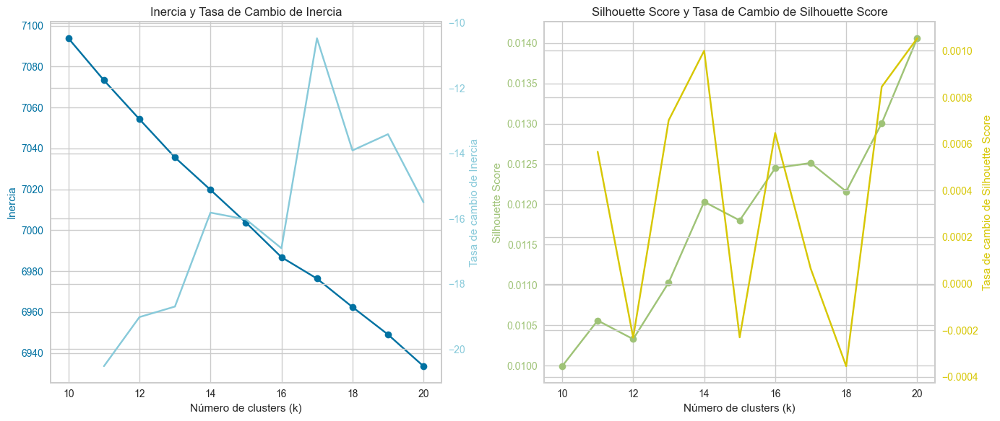

In [181]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 21)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k in k_range:
#     print(f"Comenzando KMeans para k={k}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X_vectorized)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X_vectorized, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

k_range = range(10, 21)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# Cargar
with open('kmeans_metrics.pkl', 'rb') as f:
    metrics = pickle.load(f)
inertia = metrics['inertia']
silhouette_scores = metrics['silhouette_scores']

# Calcular la tasa de cambio para la inercia y el Silhouette Score
delta_inertia = np.diff(inertia)
delta_silhouette = np.diff(silhouette_scores)

# Crear una figura con dos subgráficos (lado a lado)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Graficar la inercia en el primer subgráfico (izquierda)
ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Graficar la tasa de cambio de la inercia en el eje y derecho
ax1_twin = ax1.twinx()
ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
ax1_twin.tick_params(axis='y', labelcolor='c')

# Título y leyenda para el primer gráfico
ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# ax1.legend(loc='best')

# Graficar el Silhouette Score en el segundo subgráfico (derecha)
ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
ax2.set_xlabel('Número de clusters (k)')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

# Graficar la tasa de cambio del Silhouette Score en el eje y derecho
ax2_twin = ax2.twinx()
ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
ax2_twin.tick_params(axis='y', labelcolor='y')

# Título y leyenda para el segundo gráfico
ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# ax2.legend(loc='best')

# Mostrar el gráfico
plt.tight_layout()  # Ajusta el espacio entre los subgráficos
plt.show()

### Clustering final

In [182]:
kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X_vectorized)
df["cluster_KM"] = kmeans.predict(X_vectorized)

print(sorted(df['cluster_KM'].unique()))
df["cluster_KM"].value_counts()

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


cluster_KM
12    1660
2      709
1      684
9      614
11     535
13     508
5      471
0      413
14     396
7      350
3      299
8      272
4      238
15     206
6      197
10     170
16     161
Name: count, dtype: int64

Clasificación de un texto

In [183]:
predicted_cluster = kmeans.predict(topico_vec)
print(predicted_cluster)

[12]


## Resultados

In [184]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
df.loc[indices_knn[0], "cluster_KM"] = -1

Elegir tipo de clustering realizado:
* cluster_HC
* cluster_KM

In [185]:
clustering_method = "cluster_KM"

In [186]:
# PCA

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['pca3d_1', 'pca3d_2', 'pca3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['Document Title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'pca2d_1'], 
               y=df.loc[indices_knn[0], 'pca2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'Document Title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['pca2d_1'], 
               y=centroides_2d['pca2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['Document Title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'pca3d_1'], 
                 y=df.loc[indices_knn[0], 'pca3d_2'], 
                 z=df.loc[indices_knn[0], 'pca3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'Document Title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['pca3d_1'], 
                 y=centroides_3d['pca3d_2'], 
                 z=centroides_3d['pca3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
fig.show()

In [187]:
# UMAP

# Calcular los centroides de cada cluster
centroides_2d = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean()
centroides_3d = df.groupby(clustering_method)[['umap3d_1', 'umap3d_2', 'umap3d_3']].mean()

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales en 2D
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=df[clustering_method], colorscale='Viridis', size=3),
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['Document Title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados en 2D
fig.add_trace(
    go.Scatter(x=df.loc[indices_knn[0], 'umap2d_1'], 
               y=df.loc[indices_knn[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'Document Title'])],  
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Centroides en 2D
fig.add_trace(
    go.Scatter(x=centroides_2d['umap2d_1'], 
               y=centroides_2d['umap2d_2'], 
               mode='markers',
               marker=dict(symbol='x', color=centroides_2d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
               text=["Centroide: " + str(c) for c in centroides_2d.index],
               hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=df[clustering_method], colorscale='Viridis', size=3, opacity=1),
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df[clustering_method], data['Document Title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D
fig.add_trace(
    go.Scatter3d(x=df.loc[indices_knn[0], 'umap3d_1'], 
                 y=df.loc[indices_knn[0], 'umap3d_2'], 
                 z=df.loc[indices_knn[0], 'umap3d_3'], 
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=["Cluster: " + str(c) + "<br>Titulo: " + t for c, t in zip(df.loc[indices_knn[0], clustering_method], data.loc[indices_knn[0], 'Document Title'])],  
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Centroides en 3D
fig.add_trace(
    go.Scatter3d(x=centroides_3d['umap3d_1'], 
                 y=centroides_3d['umap3d_2'], 
                 z=centroides_3d['umap3d_3'], 
                 mode='markers',
                 marker=dict(symbol='x', color=centroides_3d.index, colorscale='Viridis', size=10, line=dict(color='black', width=2)),
                 text=["Centroide: " + str(c) for c in centroides_3d.index],
                 hovertemplate="%{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

# Sumarizacion
Nube de palabras en corpus completo y por clusters

### Corpus


Corpus completo: voltage, mmc, converter, dc, control, power, current, proposed, system, fault


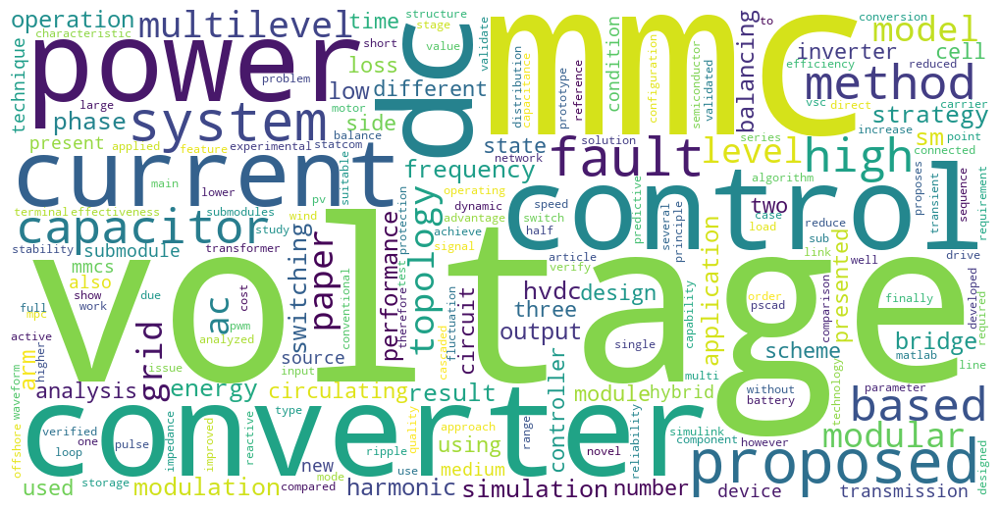

In [188]:
centroide = df_vectorized.mean(axis=0)
print(f'\nCorpus completo: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')

NubePalabrasTFIDF(centroide)

### Clusters

In [189]:
for cluster in clusters:
    cluster_data = df_vectorized[(df[clustering_method] == cluster).values]
    centroide = cluster_data.mean(axis=0)
    print(f'\nCluster {cluster}: {", ".join([words[ind] for ind in centroide.argsort()[::-1][:10]])}')
    # NubePalabrasTFIDF(centroide)


Cluster 0: circulating, current, control, mmc, arm, voltage, harmonic, controller, proposed, method

Cluster 1: dc, voltage, converter, power, transformer, ac, high, topology, proposed, control

Cluster 2: fault, dc, current, mmc, protection, circuit, hvdc, proposed, system, line

Cluster 3: drive, motor, speed, voltage, frequency, low, machine, converter, control, capacitor

Cluster 4: mpc, control, predictive, model, current, proposed, fcs, computational, method, voltage

Cluster 5: inverter, level, topology, voltage, converter, output, power, switch, proposed, source

Cluster 6: pv, power, photovoltaic, solar, grid, system, mppt, dc, maximum, inverter

Cluster 7: model, mmc, time, simulation, dynamic, system, transient, accuracy, converter, equivalent

Cluster 8: battery, storage, energy, system, bess, control, power, soc, converter, cell

Cluster 9: hvdc, control, system, mmc, grid, power, dc, voltage, transmission, ac

Cluster 10: impedance, stability, mmc, model, frequency, syst

# Documento representativo
En corpus completo y por clusters

## Centroides

In [190]:
def encontrar_mas_cercano_al_centroide(df_vectorized, data):
    centroide = df_vectorized.mean(axis=0)
    distancias = euclidean_distances(df_vectorized, [centroide])
    indice_mas_cercano = np.argmin(distancias)
    texto_mas_cercano = data.iloc[indice_mas_cercano]['Abstract']
    titulo = data.iloc[indice_mas_cercano]['Document Title']
    return titulo, texto_mas_cercano

### Corpus

In [191]:
titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
display(f"Texto mas representativo del corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {texto_mas_cercano}")

'Texto mas representativo del corpus:'

'Título: A Control Method of DC Capacitor Voltage in MMC for HVDC System using Negative Sequence Current'

'Abstract: The application of Modular Multilevel Converter (MMC) for High Voltage Direct Current (HVDC) system is expected to enhance power transmission capacity and improve power system stability. To control an MMC-HVDC system properly, the ac current, circulating current among arms and submodule (SM) capacitor voltages are considered. In the conventional balance control method of the dc capacitor voltage, the reference value of the circulating current control includes ac component as same frequency as ac grid. In this case, it is difficult to follow the reference value perfectly by proportional-integral (PI) controller. This article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current. The validity of the proposed control method is verified by a numerical simulation.'

### Clusters

In [192]:
for cluster in clusters:
    cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
    cluster_data = data[df[clustering_method] == cluster]
    titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
    display(f"Cluster {cluster}: Texto mas cercano al centroide")
    display(f"Título: {titulo}")
    display(f"Abstract: {texto_mas_cercano}")

'Cluster 0: Texto mas cercano al centroide'

'Título: A Control Method of HVDC-Modular Multilevel Converter Based on Arm Current Under the Unbalanced Voltage Condition'

'Abstract: This paper proposes an enhanced control method for a high-voltage direct-current (HVDC) modular multilevel converter (MMC). To control an MMC-HVDC system properly, the ac current, circulating current, and submodule (SM) capacitor voltage are considered. The ac-side current is a fundamental frequency component, and the circulating current is a double-line frequency component. Existing control methods control the ac current and circulating current by separating each component. However, the existing methods have a disadvantage in that the ac-side current must be separated into the positive and negative sequences for control under an unbalanced voltage condition. The circulating current consists of not only negative-sequence components but also positive- and zero-sequence components under an unbalanced voltage condition. Therefore, an additional control method is necessary to consider the positive- and zero-sequence components of the circulating current. The proposed control met

'Cluster 1: Texto mas cercano al centroide'

'Título: A multiport modular multilevel DC-DC converter'

...

'Título: Control strategies of a dc based offshore wind farm with series connected collection grid'

'Abstract: This paper presents the control strategy of a dc series offshore wind farm with an onshore modular multilevel converter (MMC). The series connection of the dc wind turbines establishes the HVDC transmission voltage level with neither offshore transformer nor centralized converter station, indicating huge savings on offshore wind farm investment. However, power production unbalance in the wind farm or bypass of any wind turbine may impose overvoltage at the outputs of several wind turbines. A global control strategy, which regulates the HVDC voltage level by controlling the onshore MMC, is thus proposed to ensure the operation of each wind turbine under a safe voltage level while no power production is lost in the wind farm. This paper first introduces the whole wind generation system. Then the steady state analysis of the dc series offshore wind farm and the overvoltage phenomenon are described, which lead to the proposal of the global control strategy. The detailed realizat

'Cluster 16: Texto mas cercano al centroide'

'Título: Modular multilevel STATCOM with energy storage'

'Abstract: A configuration of Energy storage (ES) integrated STATCOM is presented in this paper. Such type of system is generally referred as E-STATCOM (STATCOM+ES) in the literature. In this paper, a Modular Multilevel Converter (MMC) is used as a STATCOM and energy storage is integrated at the DC link of MMC. An E-STATCOM primarily functions as a STATCOM, but it has the ability to support active power at different time scale. So, separate systems, one for energy storage integration and the other for STATCOM operation can be avoided. In this paper, E-STATCOM is used to address the issues related to a PV dominated grid, e.g. power fluctuation due to variation of solar irradiance and power quality issues. The configuration is verified through simulation in PSCAD and the results show effectiveness of E-STATCOM for a PV-dominated grid.'

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [193]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
print("Texto más representativo del corpus:")
print(f"Título: {data['Document Title'].iloc[abstract00]}")
print(f"Abstract: {data['Abstract'].iloc[abstract00]}")

Texto más representativo del corpus:
Título: Transformation of the Energy System in Germany - Enhancement of System Stability by Integration of innovative Multilevel HVDC in the AC Grid
Abstract: Globally, deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well. An increasingly liberalized market will encourage trading opportunities to be identified and developed. Environmental constraints, such as energy saving, and CO2 reduction, also play an important role. The loading of existing power systems will further increase, leading to bottlenecks and reliability problems. Consequently, we have to deal with an area of conflicts between reliability of supply, environmental sustainability as well as economic efficiency. Furthermore, in Germany, the transition from well-proven Energy-Mix to the new Energy-Transition ("Energie-Wende") with large amounts of volatile Regenerative Energy Sources (RES), e.g. over 30 GW solar power on

### Clusters

In [194]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['Document Title'].iloc[abstract00]}")
display(f"Abstract: {data['Abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: Transformation of the Energy System in Germany - Enhancement of System Stability by Integration of innovative Multilevel HVDC in the AC Grid'

'Abstract: Globally, deregulation and privatization are posing new challenges on high voltage transmission and on distribution systems as well. An increasingly liberalized market will encourage trading opportunities to be identified and developed. Environmental constraints, such as energy saving, and CO2 reduction, also play an important role. The loading of existing power systems will further increase, leading to bottlenecks and reliability problems. Consequently, we have to deal with an area of conflicts between reliability of supply, environmental sustainability as well as economic efficiency. Furthermore, in Germany, the transition from well-proven Energy-Mix to the new Energy-Transition ("Energie-Wende") with large amounts of volatile Regenerative Energy Sources (RES), e.g. over 30 GW solar power on medium and even low voltage level, in combination with over 30 GW of wind power (at present - mainly onshore) plus high amounts of offshore wind power in the future (30 to 50 GW - long

In [195]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    display(f"Cluster {cluster}: Texto mas representativo")
    display(f"Título: {data['Document Title'].iloc[abstract00]}")
    display(f"Abstract: {data['Abstract'].iloc[abstract00]}")

'Cluster 0: Texto mas representativo'

'Título: Design and Implementation of a Resonant Controller to Balance the Capacitor Voltage on a HVDC Terminal Based on MMC'

'Abstract: In recent years, the High Voltage Direct Current (HVDC) based on a Modular Multilevel Converter (MMC) has become an attractive solution for the integration of Renewable Energy Sources (RES), especially wind energy, located at long distances from consumption centers. The operation of MMC terminal needs to accomplish stability in the main parameters of the electrical grid, such as voltage, phase, and frequency. To maintain these parameters in their typical values, the MMC needs to control the circulating currents, each voltage in the capacitor of the submodules, output current, and output voltage. This paper proposes a control scheme for a leg of the MMC to make the balance of the Submodule Voltage Capacitor (VSM). The proposed control scheme includes a Proportional Integral Resonant (PIR) Controller, which uses a Band-pass filter (BPF) to make the selective attenuation of undesired harmonic components. The control scheme is validated in Hardware in the Loop dSPACE and a scale

'Cluster 1: Texto mas representativo'

'Título: Cascaded modular single-stage solid-state transformer with reduced count of components'

...

'Título: Real-time Validation of a DC-link Tuning Method for an AC-AC Wind Converter in Fractional Frequency Transmission System'

'Abstract: Wind power converters with modularity and scalability features paly pivotal role in interfacing of wind farms with the medium/high-power systems. These offshore or onshore grids are vulnerable to instabilities during certain working conditions that adaptive control solutions could overcome some of those stability issues. Additionally, computational burden of existing control strategies, such as model predictive control (MPC) has caused implementation barriers. In this work, the operational performance of the Modular Multilevel Matrix Converter (M3C) is assessed to transmit power produced from offshore wind farm to interconnect with onshore AC grid. Small-signal impedance measurement-based stability analysis are not efficient to predict large-signal stability characteristics. The two-layer control design architecture is proposed to regulate the converter branch voltages and currents. The second-layer iterative controller is embedded into an integrated perturbation analysis an

'Cluster 16: Texto mas representativo'

'Título: Assessment of Sequence Extraction Methods Applied to MMC-SDBC STATCOM Under Distorted Grid Conditions'

'Abstract: Under grid distortions, Modular Multilevel Converters (MMC) must adopt proper control strategies to fulfill the power system requirements and ensure a stable operation. An inappropriate control under such conditions may lead to energy unbalances between the MMC legs, inaccurate current injection, and failure in the synchronization process. In this context, sequence extraction methods play a critical role in enhancing the performance of the control, firstly, by aiding the Phase-Locked Loop (PLL) to maintain the synchronization with the AC grid by following the positive sequence fundamental component of the voltage, secondly, by allowing accurate active and reactive currents injection via the decoupled Voltage Oriented Control (dVOC), thirdly, by properly managing the internal energy of the MMC through the circulating current control. In prior researches, some sequence extraction methods have been used for MMC STATCOM. However, the sequence extraction was not the core of the p

Anti representantes (abstracts con baja participación en el tfid vectorizer)

In [196]:
# representantes = [df_vectorized.loc[df[df[clustering_method] == idx].index].sum(axis=1).sort_values().index[0] for idx in clusters]
# for rep in representantes:
#   print('\nTítulo:')
#   display(data.iloc[rep]['Document Title'])
#   print('\nAbstract')
#   display(data.iloc[rep]['Abstract'])

## Similaridad del coseno

### Corpus

In [197]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["Document Title"].iloc[abstract00]
abstract_mas_representativo = data["Abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: A Control Method of DC Capacitor Voltage in MMC for HVDC System using Negative Sequence Current'

'Abstract: The application of Modular Multilevel Converter (MMC) for High Voltage Direct Current (HVDC) system is expected to enhance power transmission capacity and improve power system stability. To control an MMC-HVDC system properly, the ac current, circulating current among arms and submodule (SM) capacitor voltages are considered. In the conventional balance control method of the dc capacitor voltage, the reference value of the circulating current control includes ac component as same frequency as ac grid. In this case, it is difficult to follow the reference value perfectly by proportional-integral (PI) controller. This article presents a new control method of dc capacitor voltage using negative sequence of ac grid current and circulating current. The validity of the proposed control method is verified by a numerical simulation.'

### Clusters

In [198]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["Document Title"].iloc[abstract00]
    abstract_mas_representativo = data["Abstract"].iloc[abstract00]
    display(f"Cluster {cluster}: Texto mas similar a todos en el cluster")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

'Cluster 0: Texto mas similar a todos en el cluster'

'Título: Future HVDC-grids employing modular multilevel converters and hybrid DC-breakers'

'Abstract: The necessary shift from fossil fuels to regenerative sources imposes a great challenge for future power transmission. A large, meshed HVDC-Grid is proposed by several experts as the best and most efficient solution. For meshed DC-Grids, however, new and essential requirements - especially regarding availability and reliability - have to be researched very thoroughly. Fast and reliable handling of DC-faults must be ensured without disturbing the energy flow in the whole grid. The following paper deals with the key components (Modular Multilevel Converters and DC-Breakers) in large meshed HVDC-Grids. A comparison between suitable submodule topologies with DC-fault handling abilities is presented alongside with a new topology for a hybrid DC-Breaker.'

'Cluster 1: Texto mas similar a todos en el cluster'

'Título: A new three-phase hybrid five-level inverter with reduced number of high-frequency switching devices'

...

'Título: Development of high gain and efficiency photovoltaic system using multilevel boost converter topology'

'Abstract: This paper presents the analysis and operation of a PV system using multilevel dc-dc topology as a high gain converter in addition to applying Maximum Power Point Tracking (MPPT) technique. The multi-level boost converter parameters have been adjusted to achieve the high efficiency and high gain target results. In addition, a full bridge inverter is used to connect the generated power from the PV into the grid. The total system has been analyzed and then simulated using MATLAB to prove the idea. Then, a set-up of experimental results has been provided to validate the simulation results using FPGA control.'

'Cluster 16: Texto mas similar a todos en el cluster'

'Título: Control and modulation strategies for modular multilevel converter based HVDC system'

'Abstract: The modular multilevel converter (MMC) is a new kind of voltage source converter (VSC) with a high number of voltage levels and considered to be suitable for HVDC transmission. Based on circuit configuration and operation mechanism, this paper presents an mathematical model of MMC. Then the vector control strategy widely used in two-level VSC is applied to the control of MMC. Due to modular structure and cascaded connections, a very high number of voltage levels is obtained by MMC in HVDC applications, for which the nearest level modulation (NLM) become feasible. A combination of NLM and optimized capacitor voltage balancing control is presented to reduce the switching frequency as well as the switching losses of power semiconductors. Time-domain simulation performed in PSCAD/EMTDC shows that the control and modulation methods provide good steady-state and dynamic system performance and significantly reduce the switching frequency of power semiconductors.'

# Grafo de palabras

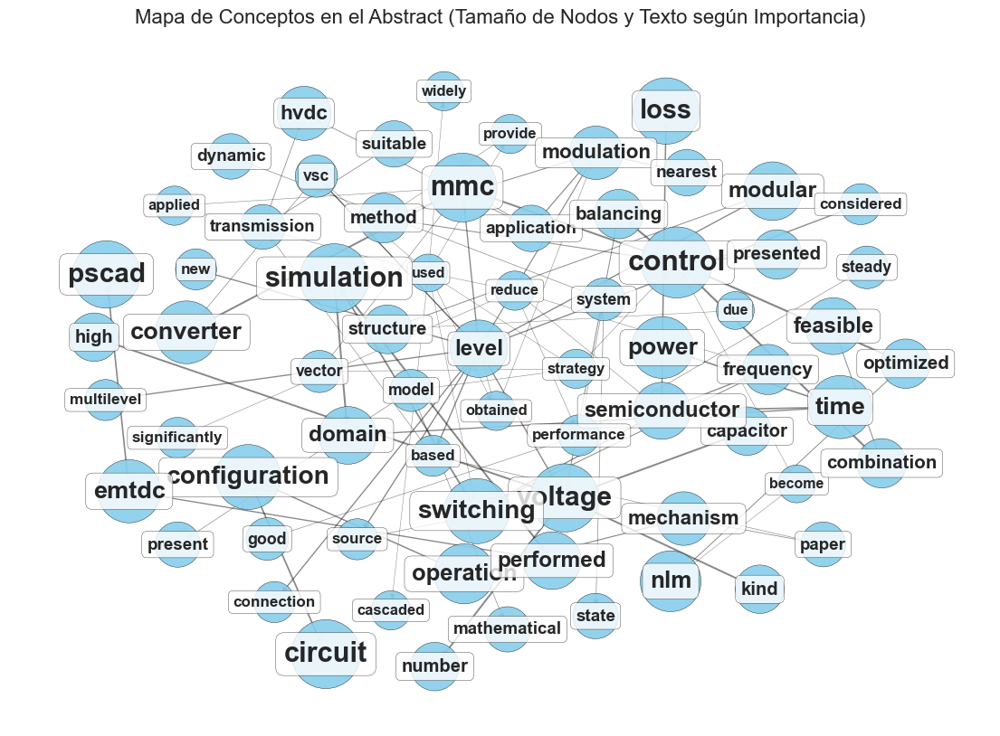

In [202]:
# Cargar modelo de spaCy
nlp = spacy.load("en_core_web_sm")

# Obtener el texto del dataframe
texto = df.loc[abstract00, "Abstract"]

# Procesar el texto con spaCy
doc = nlp(texto)

# Crear un grafo dirigido
G = nx.DiGraph()

# Añadir nodos y aristas al grafo
for token in doc:
    if not token.is_stop and not token.is_punct:
        G.add_node(token.text)

    for child in token.children:
        if not child.is_stop and not child.is_punct:
            G.add_edge(token.text, child.text)

# ---- Calcular importancia con PageRank ----
pagerank = nx.pagerank(G)  # Dict con la importancia de cada nodo
max_pr = max(pagerank.values()) if pagerank else 1  # Evitar división por 0

# Obtener posiciones iniciales con mayor separación
pos = nx.spring_layout(G, k=1.5, iterations=100)  # k más alto separa más

# ---- Aplicar algoritmo de NO SOLAPAMIENTO ----
def descomprimir_posiciones(pos, min_dist=0.15):
    """
    Ajusta las posiciones para evitar solapamiento.
    min_dist: Distancia mínima entre nodos.
    """
    nodes = list(pos.keys())
    positions = np.array(list(pos.values()))

    for _ in range(100):  # Máximo 100 iteraciones de ajuste
        moved = False
        for i, p1 in enumerate(positions):
            for j, p2 in enumerate(positions):
                if i != j:
                    dist = np.linalg.norm(p1 - p2)
                    if dist < min_dist:  # Si están muy cerca, separarlos
                        direction = (p1 - p2) / (dist + 1e-6)  # Evitar división por 0
                        positions[i] += direction * (min_dist - dist) * 0.5
                        positions[j] -= direction * (min_dist - dist) * 0.5
                        moved = True
        if not moved:
            break  # Termina si ya no hay más solapamiento

    return {nodes[i]: positions[i] for i in range(len(nodes))}

# Aplicar descompresión de posiciones
pos = descomprimir_posiciones(pos, min_dist=0.25)

# ---- Ajustar tamaño de los nodos según importancia (PageRank) ----
node_sizes = [pagerank[n] / max_pr * 3000 + 200 for n in G.nodes()]  # Más grandes si son más importantes

# ---- Ajustar tamaño de las aristas ----
edge_sizes = [50 * pagerank[u] for u, v in G.edges()]

# ---- Ajustar tamaño de la fuente según importancia ----
font_sizes = {n: pagerank[n] / max_pr * 15 + 8 for n in G.nodes()}  # Escala entre 8 y 23

# Crear la figura
plt.figure(figsize=(14, 10))

# Dibujar nodos con tamaño basado en PageRank
nx.draw_networkx_nodes(G, pos, 
                       node_size=node_sizes, 
                       node_color="skyblue", alpha=0.9, edgecolors="black")

# Dibujar bordes con grosor proporcional a la importancia del nodo origen
nx.draw_networkx_edges(G, pos, alpha=0.5, width=edge_sizes)

# Dibujar etiquetas con tamaños proporcionales a su importancia
for node, (x, y) in pos.items():
    plt.text(x, y, node, fontsize=font_sizes[node], fontweight="bold",
             bbox=dict(facecolor="white", edgecolor="black", boxstyle="round,pad=0.3", alpha=0.8),
             ha="center", va="center")

# Título y mostrar gráfico
plt.title("Mapa de Conceptos en el Abstract (Tamaño de Nodos y Texto según Importancia)", fontsize=16)
plt.axis("off")
plt.show()